# Phase 6: Is economic growth translating into development?

**The question:** between 2000 and 2025, did GDP growth in Nigeria, Kenya, Ghana, Rwanda and South Africa come with
less poverty, a fairer share for the poorest, better jobs, better living standards and longer lives?

**How this notebook is organised.** Each section asks one question, then:
1. a chart (or table) that answers it, and
2. **What this shows**: the answer in plain words, plus any caveat.

**Rules we follow:**
- **Read only from the marts** (`fct_growth_vs_development`, `fct_poverty_survey_spans`). Never raw tables: the marts are tested, documented and agreed, so every number here traces back through dbt.
- **"Moved together", never "caused".** Five countries and 21 survey pairs can show patterns, not prove causes.
- **No forward-filling poverty.** It is measured only in survey years, so we compare survey to survey.

Run top to bottom with **Shift + Enter**. Kernel: **Python (econdev)**.

## 0. Setup and loading the marts

Project id comes from `config/indicators.yml`, the same file the pipeline uses. Colours are fixed **per country**
(Nigeria is always blue, Kenya always orange...) so you never have to re-learn the legend between charts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pandas_gbq
import yaml

config = yaml.safe_load(Path("../config/indicators.yml").read_text())
PROJECT = config["bigquery"]["project"]
MARTS = f"{PROJECT}.dbt_dev"


def read_mart(name):
    return pandas_gbq.read_gbq(f"select * from `{MARTS}.{name}`", project_id=PROJECT, progress_bar_type=None)


country_year = read_mart("fct_growth_vs_development").sort_values(["country_iso3", "year"])
spans = read_mart("fct_poverty_survey_spans").sort_values(["country_iso3", "start_year"])

# One colour and one marker per country, used in every chart
COUNTRIES = ["NGA", "KEN", "GHA", "RWA", "ZAF"]
NAMES = country_year.drop_duplicates("country_iso3").set_index("country_iso3")["country_name"].to_dict()
COLORS = dict(zip(COUNTRIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MARKERS = dict(zip(COUNTRIES, ["o", "s", "^", "D", "v"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "lines.linewidth": 2, "legend.frameon": False,
})


def label_line_ends(ax, df, value_col, fmt="{:.0f}"):
    """Write each country's name at the end of its line, so colour is never the only clue."""
    ends = df.dropna(subset=[value_col]).groupby("country_iso3").tail(1).sort_values(value_col)
    min_gap = 0.06 * (df[value_col].max() - df[value_col].min())  # push labels apart if lines end close together
    label_y = []
    for value in ends[value_col]:
        label_y.append(max(value, label_y[-1] + min_gap) if label_y else value)
    for (_, row), y in zip(ends.iterrows(), label_y):
        ax.annotate(f"{NAMES[row.country_iso3]} {fmt.format(row[value_col])}", (row.year, row[value_col]),
                    xytext=(row.year + 0.4, y), textcoords="data", va="center", fontsize=9, color=INK)


print(f"country_year: {len(country_year)} rows, {country_year.year.min()}-{country_year.year.max()}")
print(f"spans:        {len(spans)} rows")

country_year: 130 rows, 2000-2025
spans:        21 rows


### Sanity check: is the data what we think it is?

Before any chart, confirm the **grain** (one row per country-year, one row per survey pair) and the row counts dbt reported.
If these fail, stop: every chart below would be wrong.

In [2]:
assert len(country_year) == 130 and not country_year.duplicated(["country_iso3", "year"]).any()
assert len(spans) == 21 and not spans.duplicated(["country_iso3", "start_year"]).any()

coverage = country_year.groupby("country_iso3")[[
    "gdp_growth_pct", "gdp_per_capita_growth_pct", "poverty_pct", "income_share_bottom20_pct", "unemployment_pct",
    "vulnerable_employment_pct", "electricity_access_pct", "mobile_per_100", "life_expectancy_years"]].count()
coverage.index = coverage.index.map(NAMES)
coverage.columns = ["GDP growth", "GDP growth per person", "Poverty", "Poorest 20% share", "Unemployment",
                    "Vulnerable employment", "Electricity", "Mobile", "Life expectancy"]
coverage

,GDP growth,GDP growth per person,Poverty,Poorest 20% share,Unemployment,Vulnerable employment,Electricity,Mobile,Life expectancy
country_iso3,,,,,,,,,
Ghana,26,26,3,3,26,26,25,25,25
Kenya,26,26,5,5,26,26,25,25,25
Nigeria,26,26,6,6,26,26,25,25,25
Rwanda,26,26,6,6,26,26,25,25,25
South Africa,26,26,6,6,26,26,25,25,25


**What this shows:** both marts have the expected grain. Growth and the two jobs measures have all 26 years.
Electricity, mobile and life expectancy have 25: the World Bank hasn't published 2025 yet. **Poverty and the poorest 20%'s
income share have only 3–6 values each.** They come from the same household surveys, in exactly the same years, which is
why they get their own survey-to-survey mart.

## 1. How fast has each economy grown?

**Sub-question 1a: on average, over 2000–2025?** We compare two periods, because the story changes after 2015.

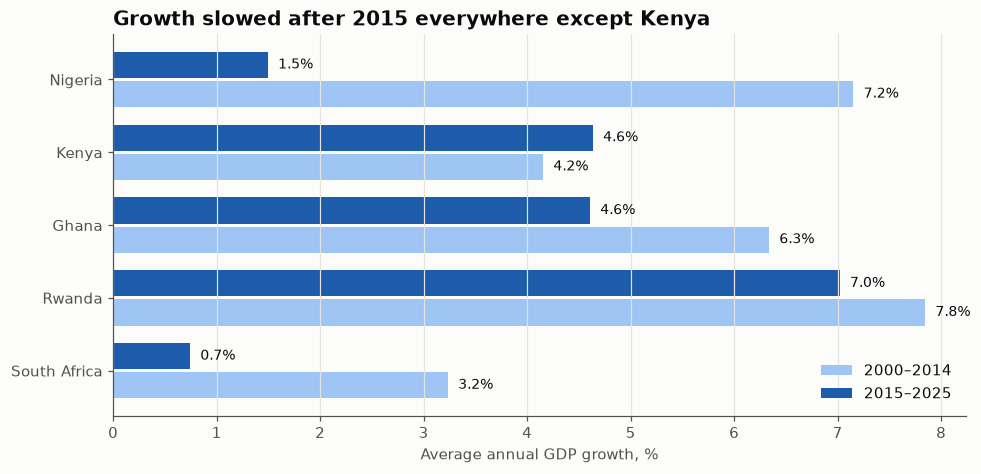

In [3]:
period = pd.cut(country_year.year, [1999, 2014, 2025], labels=["2000–2014", "2015–2025"])
avg_growth = (country_year.groupby(["country_iso3", period], observed=True).gdp_growth_pct.mean()
              .unstack().reindex(COUNTRIES))

fig, ax = plt.subplots(figsize=(10, 4.5))
y = range(len(COUNTRIES))
ax.barh([i + 0.2 for i in y], avg_growth["2000–2014"], height=0.36, color="#9ec5f4", label="2000–2014")
ax.barh([i - 0.2 for i in y], avg_growth["2015–2025"], height=0.36, color="#1c5cab", label="2015–2025")
for i, c in enumerate(COUNTRIES):
    for offset, col in [(0.2, "2000–2014"), (-0.2, "2015–2025")]:
        ax.text(avg_growth.loc[c, col] + 0.1, i + offset, f"{avg_growth.loc[c, col]:.1f}%", va="center", fontsize=9)
ax.set_yticks(list(y), [NAMES[c] for c in COUNTRIES])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Average annual GDP growth, %")
ax.set_title("Growth slowed after 2015 everywhere except Kenya")
ax.legend(loc="lower right")
plt.show()

**What this shows:**
- **Rwanda grew fastest in both periods** (7.8% then 7.0% a year), the most consistent of the five.
- **Nigeria had the biggest slowdown**: from 7.2% to 1.5% a year. With population growing ~2.5% a year, 1.5% growth means the average Nigerian got *poorer*.
- **South Africa grew slowest throughout**, falling to 0.7% a year after 2015.
- **Kenya is the only country that held steady** (4.2% → 4.6%).

**Sub-question 1b: was growth steady, or did it swing?** Yearly growth is noisy, so we plot the **5-year rolling average** from the mart.
It starts in 2004, the first year with 5 years of data behind it.

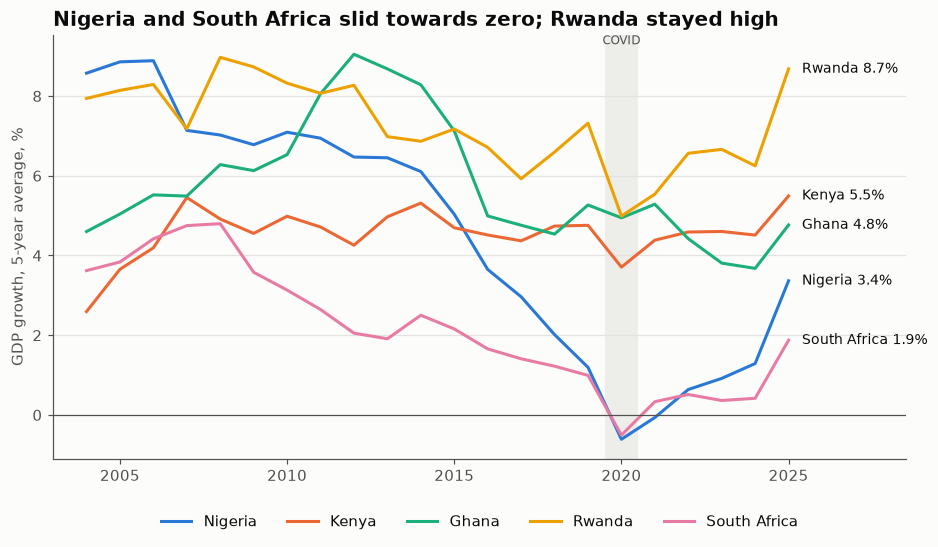

In [4]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.gdp_growth_5yr_avg, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "gdp_growth_5yr_avg", fmt="{:.1f}%")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.axvspan(2019.5, 2020.5, color=GRID, alpha=0.6, linewidth=0)
ax.text(2020, ax.get_ylim()[1], "COVID", ha="center", va="top", fontsize=8, color=MUTED)
ax.set_xlim(2003, 2028.5)
ax.set_ylabel("GDP growth, 5-year average, %")
ax.set_title("Nigeria and South Africa slid towards zero; Rwanda stayed high")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

**What this shows:** the gap between countries **widened over time**. Nigeria's average fell from about 9% in 2006
to just below zero in 2020 (the 2016 oil-price recession, then COVID). South Africa drifted from ~4% to near zero.
Rwanda and Kenya stayed steady. 2020 was the only year all five were hit at once.

**Reading tip:** the jump in 2025 (Nigeria 1.3% → 3.4%) is mostly a rolling-average effect, not a boom. 2020 has just dropped
out of the 5-year window, so the average rises even though 2025 itself was an ordinary year (4.0%).

**Sub-question 1c: how much of that growth reached the average person?** GDP growth counts the whole economy. If the
population grows 2–3% a year, the economy has to grow that fast just for the average person to stand still. **GDP growth
per person** takes population growth out.

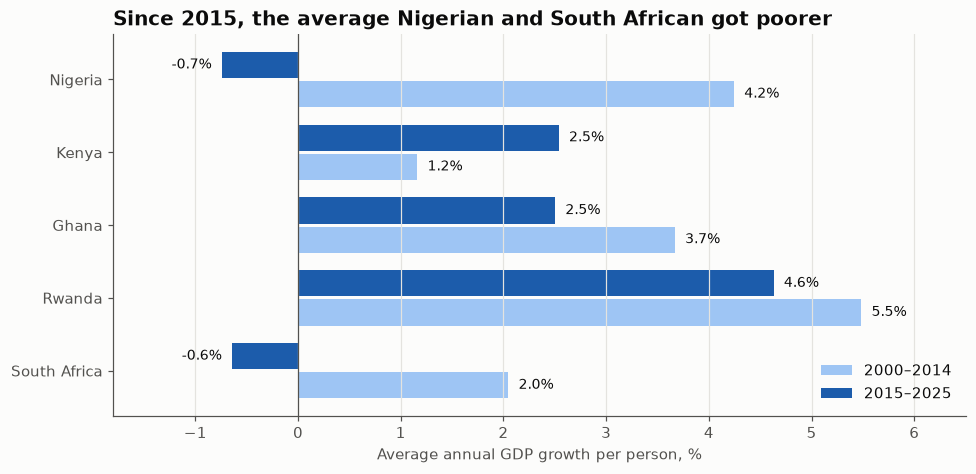

In [5]:
avg_pc = (country_year.groupby(["country_iso3", period], observed=True).gdp_per_capita_growth_pct.mean()
          .unstack().reindex(COUNTRIES))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh([i + 0.2 for i in y], avg_pc["2000–2014"], height=0.36, color="#9ec5f4", label="2000–2014")
ax.barh([i - 0.2 for i in y], avg_pc["2015–2025"], height=0.36, color="#1c5cab", label="2015–2025")
for i, c in enumerate(COUNTRIES):
    for offset, col in [(0.2, "2000–2014"), (-0.2, "2015–2025")]:
        v = avg_pc.loc[c, col]
        ax.text(v + (0.1 if v >= 0 else -0.1), i + offset, f"{v:.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_yticks(list(y), [NAMES[c] for c in COUNTRIES])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(-1.8, 6.5)
ax.set_xlabel("Average annual GDP growth per person, %")
ax.set_title("Since 2015, the average Nigerian and South African got poorer")
ax.legend(loc="lower right")
plt.show()

**What this shows:** per person, the picture is starker.
- **Nigeria (−0.7% a year) and South Africa (−0.6%) went backwards after 2015.** Their economies still grew a little, but more slowly than their populations.
- **Rwanda is still the leader** at 4.6% a year per person.
- **Kenya improved** from 1.2% to 2.5% per person, the only country to speed up.

**Answer to Q1:** growth was strong in the 2000s, but since 2015 only **Rwanda, Kenya and Ghana** have kept growing faster
than their populations. In Nigeria and South Africa, the average person is now getting poorer.

## 2. Did poverty fall?

Poverty = % of people living on less than **$3.00 a day** (2021 prices). We plot **only real survey years** (dots).
The dashed lines just connect surveys: we have no data between them, so we don't pretend to.

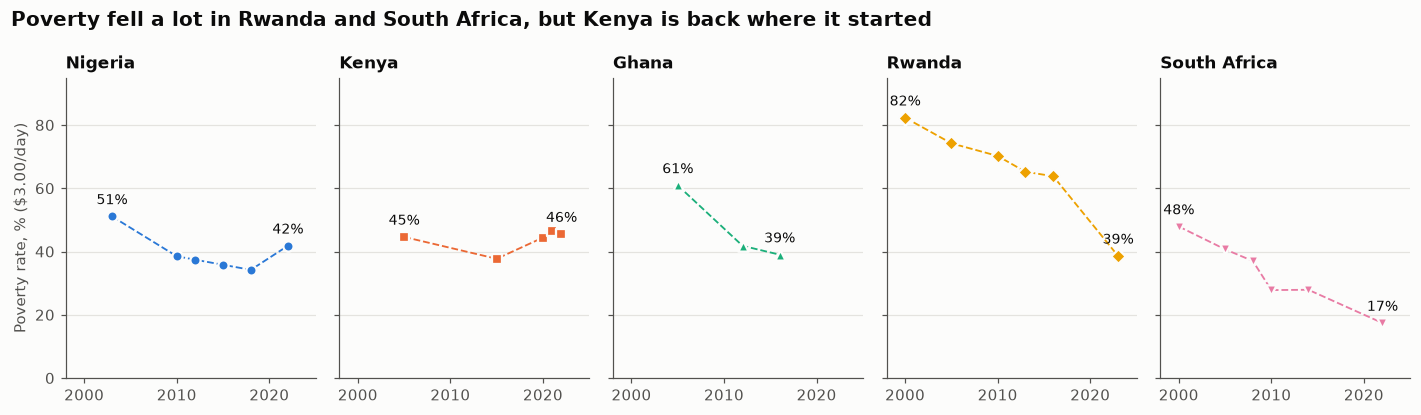

,first_year,first_pct,last_year,last_pct,change_pp
country_iso3,,,,,
Nigeria,2003,51.1,2022,41.8,-9.3
Kenya,2005,44.6,2022,45.5,0.9
Ghana,2005,60.9,2016,39.0,-21.9
Rwanda,2000,82.3,2023,38.6,-43.7
South Africa,2000,47.9,2022,17.4,-30.5


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.8), sharey=True)
surveys = country_year[country_year.is_poverty_survey_year]
for ax, c in zip(axes, COUNTRIES):
    d = surveys[surveys.country_iso3 == c]
    ax.plot(d.year, d.poverty_pct, color=COLORS[c], linestyle="--", linewidth=1.2)
    ax.scatter(d.year, d.poverty_pct, color=COLORS[c], marker=MARKERS[c], s=45, zorder=3,
               edgecolor="#fcfcfb", linewidth=1.5)
    first, last = d.iloc[0], d.iloc[-1]
    ax.annotate(f"{first.poverty_pct:.0f}%", (first.year, first.poverty_pct), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
    ax.annotate(f"{last.poverty_pct:.0f}%", (last.year, last.poverty_pct), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
    ax.set_title(NAMES[c], fontsize=11)
    ax.set_xlim(1998, 2025)
    ax.set_xticks([2000, 2010, 2020])
axes[0].set_ylabel("Poverty rate, % ($3.00/day)")
axes[0].set_ylim(0, 95)
fig.suptitle("Poverty fell a lot in Rwanda and South Africa, but Kenya is back where it started",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

first_last = surveys.groupby("country_iso3").agg(first_year=("year", "first"), first_pct=("poverty_pct", "first"),
                                                last_year=("year", "last"), last_pct=("poverty_pct", "last"))
first_last["change_pp"] = first_last.last_pct - first_last.first_pct
first_last.reindex(COUNTRIES).rename(index=NAMES).round(1)

**What this shows:**
- **Rwanda had the biggest drop:** 82% → 39% (2000 → 2023), most of it between the 2016 and 2023 surveys.
- **South Africa fell** from 48% to 17%, despite having the **slowest growth** of the five. Hold on to that for Q3.
- **Nigeria and Ghana fell, then stalled.** Nigeria's poverty **rose** again between 2018 and 2022 (34% → 42%).
- **Kenya ended about where it started** (45% in 2005, 46% in 2022), after rising after 2015.

**Caveat:** Ghana has only 3 surveys and the latest is 2016, so we don't know what happened after that.

## 3. The core question: between surveys, did faster growth go with faster poverty reduction?

This uses `fct_poverty_survey_spans`: one dot = one pair of back-to-back surveys in one country.

**Why "per year"?** Spans range from 1 to 10 years. A 10-point drop over 10 years is slower than a 5-point drop over 2,
so we divide the poverty change by the span length to compare them fairly.

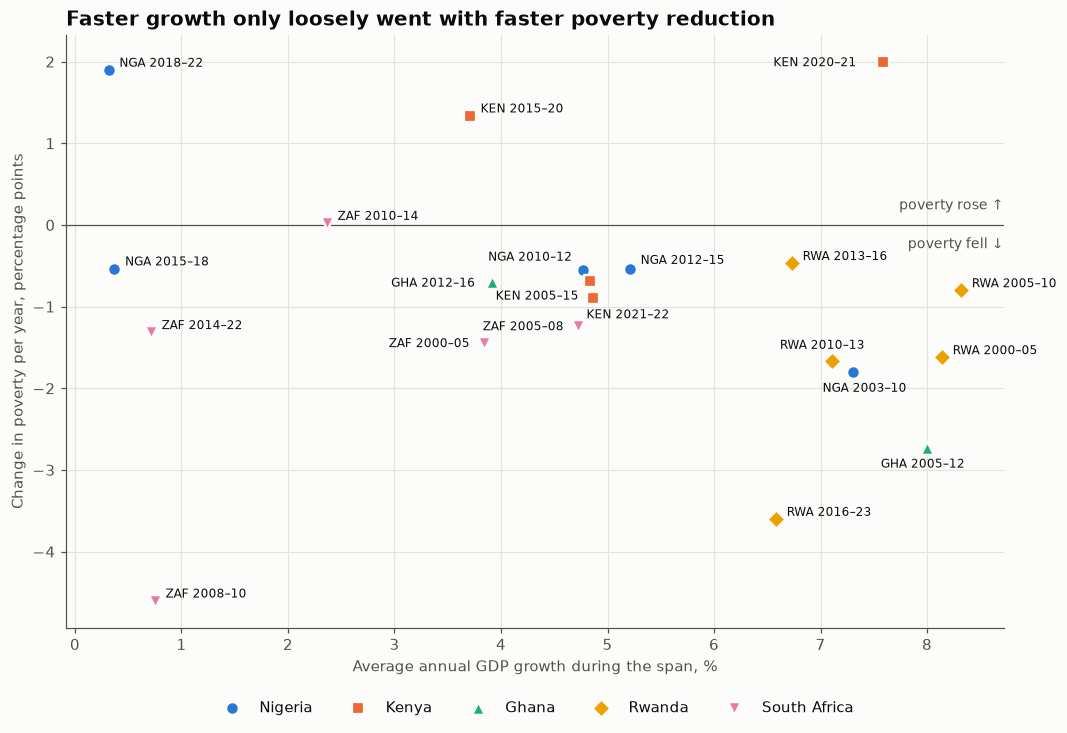

Correlation between growth and yearly poverty change: -0.11  (−1 = perfect 'more growth, less poverty', 0 = no link)
Spans where poverty fell: 17 of 21
Same correlation using growth per person: -0.15


In [7]:
spans["poverty_change_pp_per_year"] = spans.poverty_change_pp / spans.span_years

fig, ax = plt.subplots(figsize=(11, 7))
for c in COUNTRIES:
    d = spans[spans.country_iso3 == c]
    ax.scatter(d.avg_gdp_growth_pct, d.poverty_change_pp_per_year, color=COLORS[c], marker=MARKERS[c],
               s=70, label=NAMES[c], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.grid(axis="x", visible=True)

# Label every span as "country code + years", e.g. "NGA 2018–22".
# Most labels sit just right of the dot; the crowded ones around 5% growth are nudged by hand.
nudge = {("NGA", 2010): (-62, 6), ("KEN", 2005): (-62, -12), ("GHA", 2012): (-66, -3), ("KEN", 2021): (-4, -13),
         ("NGA", 2012): (7, 3), ("ZAF", 2005): (-62, -3), ("ZAF", 2000): (-62, -3), ("KEN", 2020): (-72, -3),
         ("GHA", 2005): (-30, -13), ("RWA", 2010): (-34, 8), ("NGA", 2003): (-20, -13)}
for _, r in spans.iterrows():
    offset = nudge.get((r.country_iso3, r.start_year), (7, 2))
    ax.annotate(f"{r.country_iso3} {r.start_year}–{str(r.end_year)[2:]}", (r.avg_gdp_growth_pct, r.poverty_change_pp_per_year),
                xytext=offset, textcoords="offset points", fontsize=8, color=INK)

ax.text(ax.get_xlim()[1], 0.15, "poverty rose ↑", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.text(ax.get_xlim()[1], -0.15, "poverty fell ↓", ha="right", va="top", fontsize=9, color=MUTED)
ax.set_xlabel("Average annual GDP growth during the span, %")
ax.set_ylabel("Change in poverty per year, percentage points")
ax.set_title("Faster growth only loosely went with faster poverty reduction")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

r = spans[["avg_gdp_growth_pct", "poverty_change_pp_per_year"]].corr().iloc[0, 1]
print(f"Correlation between growth and yearly poverty change: {r:.2f}  (−1 = perfect 'more growth, less poverty', 0 = no link)")
print(f"Spans where poverty fell: {(spans.poverty_change_pp < 0).sum()} of {len(spans)}")
r_pc = spans[["avg_gdp_per_capita_growth_pct", "poverty_change_pp_per_year"]].corr().iloc[0, 1]
print(f"Same correlation using growth per person: {r_pc:.2f}")

**What this shows:** the correlation is about **−0.1**: across these 21 spans, growth rate and poverty change
barely moved together. Most dots sit below zero (poverty fell in 17 of 21 spans), but **how fast it fell had little to do with how fast the economy grew.**

The exceptions tell the story better than the average:
- **Growth without poverty reduction:** Kenya 2015–2020 grew 3.7% a year, yet poverty *rose* 6.7 points. Kenya 2020–2021 (top right) grew 7.6% and poverty still rose, but that's a single-year span bouncing back from COVID, so don't read much into it.
- **Poverty reduction without growth:** South Africa 2008–2010 and 2014–2022 cut poverty sharply on growth below 1%.
  Something other than growth was at work. South Africa's social grants are one candidate worth investigating, but **this data can't tell us**.
- **No growth, more poverty:** Nigeria 2018–2022 grew 0.3% a year (well below population growth) and poverty rose 7.6 points. This fits "no growth hurts".
- **Growth and poverty reduction together:** Ghana 2005–2012 and Rwanda 2016–2023.

**Answer to Q3:** growth seems to **help but not guarantee** poverty reduction. *Who* benefits from growth matters as much as how big it is.

Using growth **per person** instead barely changes it (about −0.15), so the weak link isn't caused by population growth.

**Caveat:** 21 points is a small sample, and 2 of them are 1-year Kenya spans, which are noisy. A correlation this
weak on a sample this small is a reason to investigate, not a conclusion.

## 4. Did growth reach the poorest?

Q3 suggests that *who* benefits matters. We can measure that directly: the **share of all income (or consumption) that goes
to the poorest 20% of people**. If it rises, the poorest got a bigger slice of the pie. It comes from the same household
surveys as poverty, so we compare **first and latest survey** only.

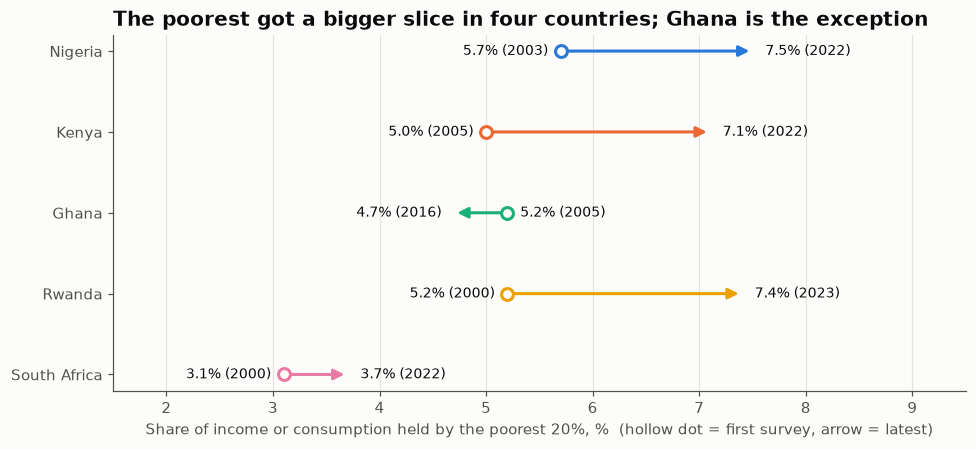

Correlation between growth and the yearly change in the poorest 20%'s share, across 21 spans: -0.00


In [8]:
share = surveys.groupby("country_iso3").agg(first_year=("year", "first"), first_pct=("income_share_bottom20_pct", "first"),
                                            last_year=("year", "last"), last_pct=("income_share_bottom20_pct", "last")).reindex(COUNTRIES)

fig, ax = plt.subplots(figsize=(10, 4.2))
for i, c in enumerate(COUNTRIES):
    r = share.loc[c]
    ax.annotate("", xy=(r.last_pct, i), xytext=(r.first_pct, i),
                arrowprops=dict(arrowstyle="-|>", color=COLORS[c], lw=2, mutation_scale=14))
    ax.scatter([r.first_pct], [i], color="#fcfcfb", edgecolor=COLORS[c], linewidth=2, s=60, zorder=3)
    left, right = sorted([(r.first_pct, int(r.first_year)), (r.last_pct, int(r.last_year))])
    ax.text(left[0] - 0.12, i, f"{left[0]:.1f}% ({left[1]})", ha="right", va="center", fontsize=9)
    ax.text(right[0] + 0.12, i, f"{right[0]:.1f}% ({right[1]})", ha="left", va="center", fontsize=9)
ax.set_yticks(range(len(COUNTRIES)), [NAMES[c] for c in COUNTRIES])
ax.invert_yaxis()
ax.set_xlim(1.5, 9.5)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Share of income or consumption held by the poorest 20%, %  (hollow dot = first survey, arrow = latest)")
ax.set_title("The poorest got a bigger slice in four countries; Ghana is the exception")
plt.show()

spans["bottom20_change_pp_per_year"] = spans.bottom20_change_pp / spans.span_years
r_share = spans[["avg_gdp_growth_pct", "bottom20_change_pp_per_year"]].corr().iloc[0, 1]
print(f"Correlation between growth and the yearly change in the poorest 20%'s share, across 21 spans: {r_share:.2f}")

**What this shows:**
- **The poorest 20% got a bigger slice in Nigeria, Kenya, Rwanda and South Africa.** Rwanda (5.2% → 7.4%) and Kenya (5.0% → 7.1%) moved the most.
- **Ghana went the other way** (5.2% → 4.7%): during its fast growth, better-off people gained more than the poorest.
- **South Africa is by far the most unequal.** Even after improving, its poorest 20% hold only 3.7% of all income. In a perfectly equal country they'd hold 20%.
- **How fast the economy grew tells us nothing about whether the poorest gained** (correlation about 0 across the 21 spans).

**A puzzle worth flagging:** Kenya's poorest got a bigger slice *and* GDP per person grew, yet its poverty rate is back where
it was in 2005. GDP and household surveys measure different things, and in Kenya they tell different stories. That's a question for
deeper research, not something this data can settle.

**Answer to Q4:** in most countries the poorest gained ground relative to everyone else, but **not because of faster growth**.
Ghana grew fast and the poorest fell behind.

## 5. Did growth create jobs, and better ones?

Unemployment = % of the labour force without work but looking for it (**modelled ILO estimates**, not direct surveys every year).

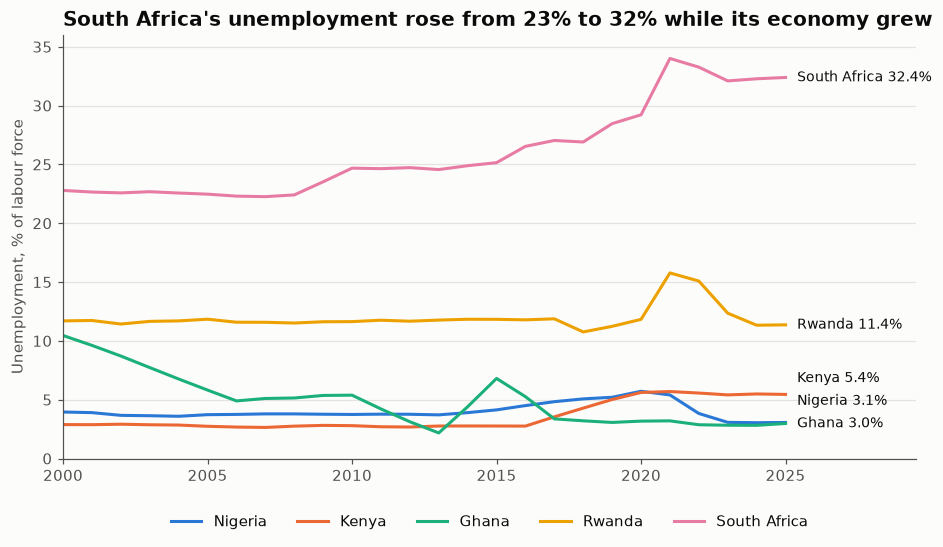

year,2000,2025,change_pp
country_iso3,,,
Nigeria,4.0,3.1,-0.9
Kenya,2.9,5.4,2.6
Ghana,10.5,3.0,-7.5
Rwanda,11.7,11.4,-0.3
South Africa,22.8,32.4,9.6


In [9]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.unemployment_pct, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "unemployment_pct", fmt="{:.1f}%")
ax.set_xlim(2000, 2029.5)
ax.set_ylim(0, 36)
ax.set_ylabel("Unemployment, % of labour force")
ax.set_title("South Africa's unemployment rose from 23% to 32% while its economy grew")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

change = country_year[country_year.year.isin([2000, 2025])].pivot(index="country_iso3", columns="year", values="unemployment_pct")
change["change_pp"] = change[2025] - change[2000]
change.reindex(COUNTRIES).rename(index=NAMES).round(1)

**What this shows:**
- **South Africa is the outlier:** unemployment climbed from 23% to 32%, with no year of real improvement. Its slow growth didn't create enough jobs.
- **Rwanda stayed flat at ~12%** despite the fastest growth (apart from a COVID spike to 16% in 2021).
- **Ghana is the one case where unemployment fell while the economy grew**: from 10.5% in 2000 to about 5% by 2006, and 3% today.
- **Nigeria and Kenya sit low (3–6%)**, and Kenya's roughly doubled after 2016.

**Big caveat: low unemployment ≠ good jobs.** In economies where most work is informal (street trading, small farms),
people can't afford to be "unemployed", so they take any work. Nigeria's 3% doesn't mean its labour market is healthier than South Africa's.
That's why we look at vulnerable employment next.

**Sub-question 5b: did work become more secure?** **Vulnerable employment** is the share of workers who work for
themselves or for family without pay: street traders, smallholder farmers. It's the closest measure we have of informal,
insecure work.

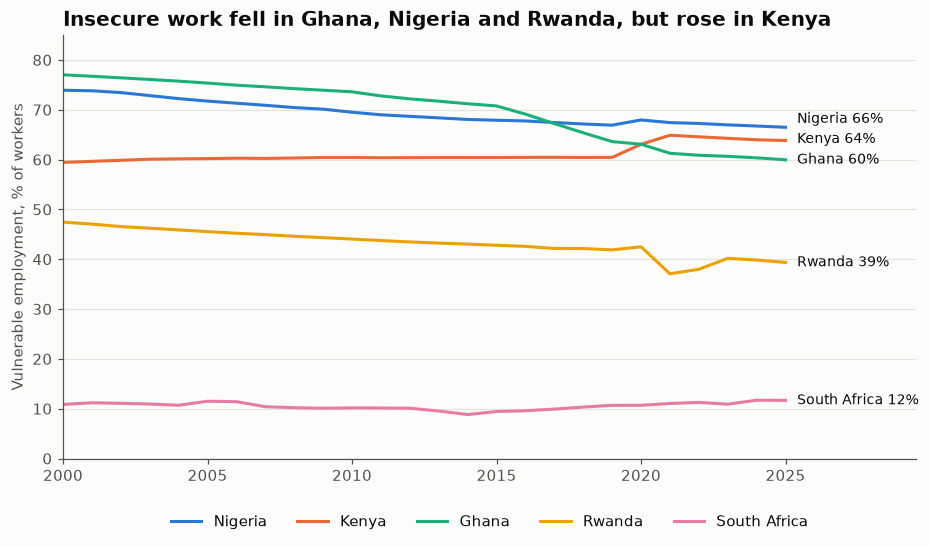

In [10]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.vulnerable_employment_pct, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "vulnerable_employment_pct", fmt="{:.0f}%")
ax.set_xlim(2000, 2029.5)
ax.set_ylim(0, 85)
ax.set_ylabel("Vulnerable employment, % of workers")
ax.set_title("Insecure work fell in Ghana, Nigeria and Rwanda, but rose in Kenya")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

**What this shows:**
- **This is the hidden side of low unemployment.** In Nigeria two-thirds of workers are in vulnerable jobs, and in Ghana and Kenya about 60%. That's why their unemployment rates of 3–6% look so low.
- **Ghana improved the most** (77% → 60%), with Nigeria (74% → 67%) and Rwanda (47% → 40%) also improving.
- **Kenya went backwards** (59% → 64%), mostly after 2018, despite steady growth.
- **South Africa is the opposite case:** only ~12% of workers are in vulnerable jobs, but 32% of the labour force is unemployed. Its workers are either in formal jobs or have no job at all.

**Answer to Q5:** growth didn't bring unemployment down, but in the three countries where vulnerable work fell, jobs became
slightly more secure. Kenya, despite steady growth, moved the other way.

## 6. Did living standards and health improve?

Three measures people feel directly: **electricity at home**, **a mobile phone**, and **how long people live**.

**Sub-question 6a: electricity.**

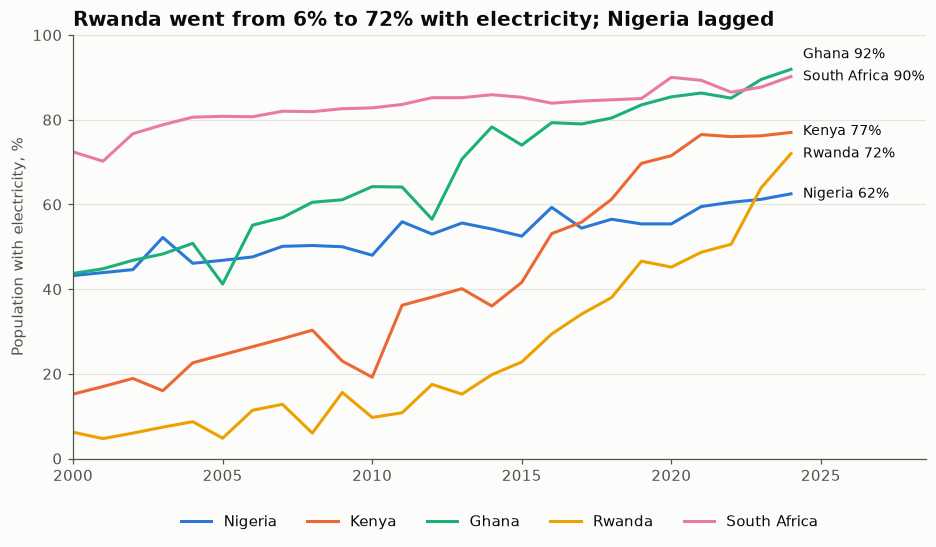

In [11]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.electricity_access_pct, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "electricity_access_pct", fmt="{:.0f}%")
ax.set_xlim(2000, 2028.5)
ax.set_ylim(0, 100)
ax.set_ylabel("Population with electricity, %")
ax.set_title("Rwanda went from 6% to 72% with electricity; Nigeria lagged")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

**What this shows:**
- **Rwanda had the biggest gain:** from 6% of people with electricity in 2000 to 72% in 2024. The jump after 2021 (49% → 72%) is unusually fast, and probably includes off-grid solar. Worth checking the World Bank's notes before quoting it.
- **Kenya went from 15% to 77%,** and Ghana reached 92%, level with South Africa (90%).
- **Nigeria improved the least,** from 43% to 62%. A third of Nigerians still have no electricity.

**Sub-question 6b: mobile phones.** Mobile subscriptions per 100 people: a common measure of access to communication and mobile money.

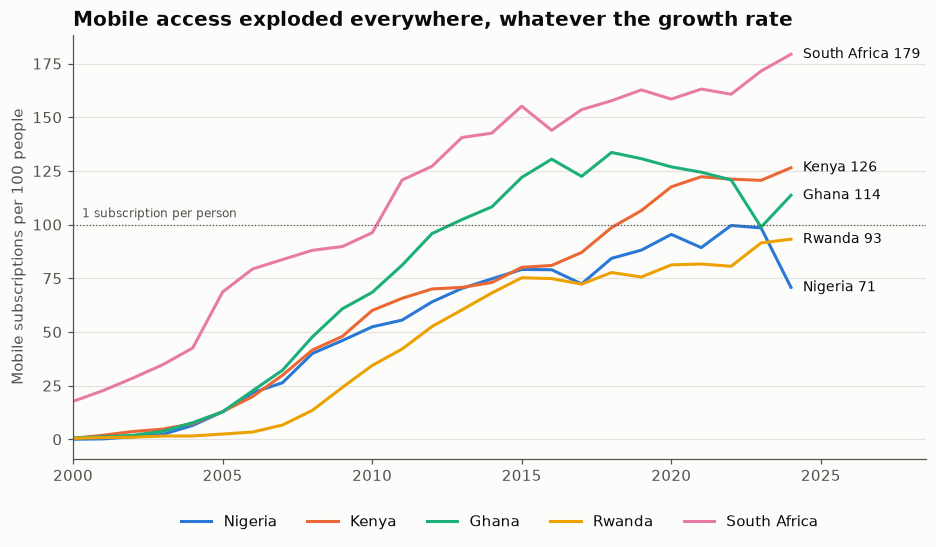

In [12]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.mobile_per_100, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "mobile_per_100")
ax.axhline(100, color=MUTED, linewidth=0.8, linestyle=":")
ax.text(2000.3, 102, "1 subscription per person", fontsize=8, color=MUTED, va="bottom")
ax.set_xlim(2000, 2028.5)
ax.set_ylabel("Mobile subscriptions per 100 people")
ax.set_title("Mobile access exploded everywhere, whatever the growth rate")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

**What this shows:** all five countries went from almost no mobile subscriptions in 2000 to **70–180 per 100 people by 2024**.
It spread **regardless of growth**: slow-growing South Africa leads (179), and fast-growing Rwanda is lowest (93).

**Watch-outs:**
- **Over 100 doesn't mean everyone has a phone.** It counts *subscriptions*, and many people have several SIM cards. It measures market size, not how many people are connected.
- **Sudden drops are usually rule changes, not people giving up phones.** Ghana dipped in 2023 (121 → 99) and **Nigeria dropped in 2024 (100 → 71)** . Both countries had campaigns around then to cut off SIM cards that weren't registered to a national ID. Check that before using the numbers.

Mobile access is the clearest improvement in the data, and the one least tied to GDP growth. It sets up **Project 3 (mobile money)**.

**Sub-question 6c: are people living longer?**

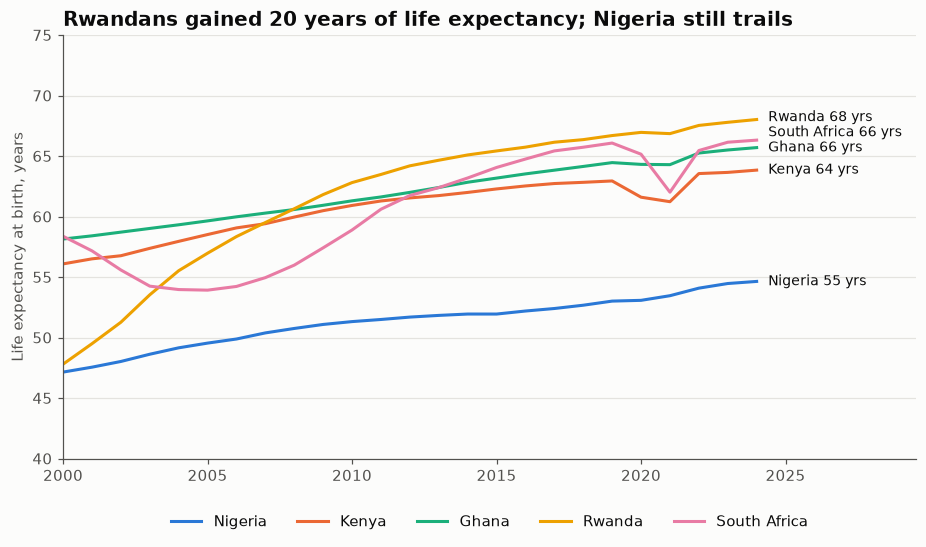

year,2000,2024,gain_years
country_iso3,,,
Nigeria,47.1,54.6,7.5
Kenya,56.1,63.8,7.8
Ghana,58.1,65.7,7.6
Rwanda,47.8,68.0,20.2
South Africa,58.4,66.3,7.9


In [13]:
fig, ax = plt.subplots()
for c in COUNTRIES:
    d = country_year[country_year.country_iso3 == c]
    ax.plot(d.year, d.life_expectancy_years, color=COLORS[c], label=NAMES[c])
label_line_ends(ax, country_year, "life_expectancy_years", fmt="{:.0f} yrs")
ax.set_xlim(2000, 2029.5)
ax.set_ylim(40, 75)
ax.set_ylabel("Life expectancy at birth, years")
ax.set_title("Rwandans gained 20 years of life expectancy; Nigeria still trails")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

life = country_year[country_year.year.isin([2000, 2024])].pivot(index="country_iso3", columns="year", values="life_expectancy_years")
life["gain_years"] = life[2024] - life[2000]
life.reindex(COUNTRIES).rename(index=NAMES).round(1)

**What this shows:**
- **Everyone lives longer than in 2000**, but the gains differ hugely. **Rwanda gained 20 years** (48 → 68), the most of the five.
- **South Africa fell first** (58 in 2000 to 54 by the mid-2000s, during the HIV/AIDS crisis), then recovered to 66 as treatment spread.
- **Apart from Rwanda, every country gained 7–8 years.** Nigeria still has the lowest life expectancy (55), lower than Rwanda's was in 2009.
- **Kenya and South Africa dipped in 2021** (COVID), then recovered.

**Answer to Q6:** living standards and health improved in **every** country, whatever the growth rate. But the biggest gains
(Rwanda in electricity and health) came with the fastest growth, and Nigeria, with the weakest recent growth, gained the least electricity and still has the shortest lives.

## 7. Putting it together: a scorecard per country

In [14]:
by_year = lambda col: country_year.set_index(["country_iso3", "year"])[col].unstack()
unemp, vuln = by_year("unemployment_pct"), by_year("vulnerable_employment_pct")
elec, life_exp, mobile = by_year("electricity_access_pct"), by_year("life_expectancy_years"), by_year("mobile_per_100")

scorecard = pd.DataFrame({
    "Avg GDP growth 2000–25, %": country_year.groupby("country_iso3").gdp_growth_pct.mean(),
    "Avg growth per person, %": country_year.groupby("country_iso3").gdp_per_capita_growth_pct.mean(),
    "Poverty change, pp": first_last.change_pp,
    "Poorest 20% share change, pp": share.last_pct - share.first_pct,
    "Unemployment change, pp": unemp[2025] - unemp[2000],
    "Vulnerable work change, pp": vuln[2025] - vuln[2000],
    "Electricity 2024, %": elec[2024],
    "Life expectancy gain, years": life_exp[2024] - life_exp[2000],
    "Mobile per 100, 2024": mobile[2024],
}).reindex(COUNTRIES).rename(index=NAMES).round(1)

(scorecard.style.format("{:.1f}")
    .background_gradient(subset=["Poverty change, pp"], cmap="Blues_r")
    .set_caption("Development scorecard, sorted as in every chart above"))

,"Avg GDP growth 2000–25, %","Avg growth per person, %","Poverty change, pp","Poorest 20% share change, pp","Unemployment change, pp","Vulnerable work change, pp","Electricity 2024, %","Life expectancy gain, years","Mobile per 100, 2024"
country_iso3,,,,,,,,,
Nigeria,4.8,2.1,-9.3,1.8,-0.9,-7.4,62.5,7.5,70.8
Kenya,4.4,1.7,0.9,2.1,2.6,4.4,77.0,7.8,126.5
Ghana,5.6,3.2,-21.9,-0.5,-7.5,-17.1,91.9,7.6,113.6
Rwanda,7.5,5.1,-43.7,2.2,-0.3,-8.1,72.0,20.2,93.2
South Africa,2.2,0.9,-30.5,0.6,9.6,0.8,90.2,7.9,179.3


**The answer to the main question:** **only partly.**

- **Growth and development moved together in Rwanda**: fastest growth (per person too), the biggest fall in poverty, a bigger share for the poorest, electricity from 6% to 72%, and 20 more years of life. Only unemployment didn't improve.
- **South Africa improved without much growth**: poverty fell sharply and the poorest gained a little, but unemployment rose by 10 points and income per person has been falling since 2015.
- **Kenya is the puzzle:** steady growth and a bigger share for the poorest, yet poverty is back where it was in 2005 and insecure work rose.
- **Nigeria shows what happens when growth stops:** income per person has fallen since 2015, poverty rose again, it gained the least electricity, and it still has the lowest life expectancy.
- **Ghana grew fast and work became more secure,** but the poorest got a *smaller* slice.
- **Electricity, mobile phones and life expectancy improved everywhere**, whatever the growth rate.

**In one sentence:** across these five countries, GDP growth **helped but didn't guarantee** better lives. Who benefits from growth mattered as much as how fast it was.

## 7. Limitations (say these before anyone asks)

1. **Poverty is sparse:** 3–6 surveys per country, at irregular intervals. Ghana's latest is 2016. Survey-to-survey changes can also reflect changes in survey methods.
2. **Unemployment and vulnerable employment are modelled ILO estimates,** not yearly measurements.
3. **Mobile counts subscriptions, not people,** and the sharp drops (Ghana 2023, Nigeria 2024) probably reflect SIM-registration rules, not real changes.
4. **Small sample:** 5 countries, 21 survey spans. Patterns, not proof.
5. **Correlation, not causation:** nothing here says growth *caused* anything. Other factors (social grants, oil prices, conflict, population growth) aren't in the data.
6. **The poorest 20%'s share mixes income and consumption,** depending on the country's survey, so compare changes within a country rather than levels across countries.
7. **Rwanda's electricity jump after 2021** may reflect a change in what counts as access (for example, off-grid solar).